In [ ]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

In [ ]:
df=pd.read_csv('/content/Ice_cream selling data.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Temperature (°C)         49 non-null     float64
 1   Ice Cream Sales (units)  49 non-null     float64
dtypes: float64(2)
memory usage: 916.0 bytes


In [ ]:
df.describe()

,Temperature (°C),Ice Cream Sales (units)
count,49.000000,49.000000
mean,0.271755,15.905308
std,2.697672,12.264682
min,-4.662263,0.328626
25%,-2.111870,4.857988
50%,0.688781,12.615181
75%,2.784836,25.142082
max,4.899032,41.842986


In [ ]:
df.head()

,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


In [ ]:
df.shape

(49, 2)

In [ ]:
# Check duplicate records
print(df.duplicated().sum())
# Remove duplicates if any
df.drop_duplicates(inplace=True)

0


<Axes: ylabel='Temperature (°C)'>

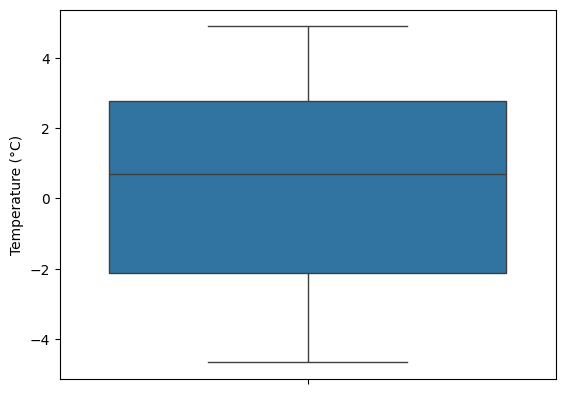

In [ ]:
#Outlier detection
sns.boxplot(df['Temperature (°C)'])

In [ ]:
x=df['Temperature (°C)']
y=df['Ice Cream Sales (units)']

Text(0, 0.5, 'Ice Cream Sales (units)')

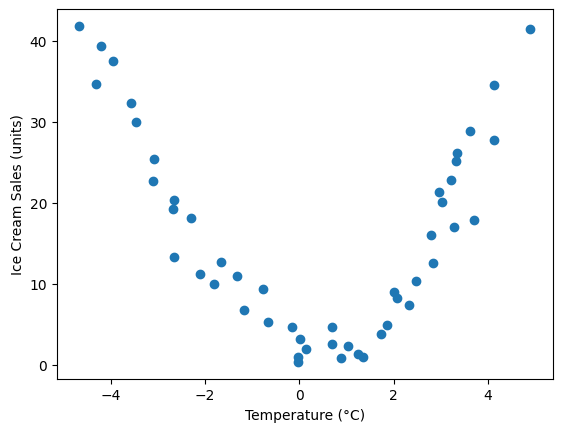

In [ ]:
plt.scatter(x,y)
plt.xlabel('Temperature (°C)')
plt.ylabel('Ice Cream Sales (units)')

In [ ]:
# Split the dataset into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=123)

In [ ]:
print(f"Number of instances for training: {len(x_train)}")
print(f"Number of instances for testing: {len(x_test)}")

Number of instances for training: 39
Number of instances for testing: 10


In [ ]:
poly_features=PolynomialFeatures(degree=2)
x_train_poly = poly_features.fit_transform(x_train.to_frame())

In [ ]:
lr_model=LinearRegression()
lr_model.fit(x_train_poly,y_train)

LinearRegression()

In [ ]:
model.fit(x_train_poly, y_train)
print("Model Trained Successfully")

Model Trained Successfully


In [ ]:
x_test_poly = poly_features.transform(x_test.to_frame())
y_pred = lr_model.predict(x_test_poly)
df=pd.DataFrame({'Actual':y_test,'Predicted':y_pred})
print(df)

       Actual  Predicted
10  13.275828  18.799936
13  10.012868  11.070250
30   3.782570   7.133564
48  41.514822  43.160544
18   5.210163   4.655879
0   41.842986  48.115345
40  22.839406  19.289363
12  11.218294  13.495525
29   0.953115   5.303529
8   19.226970  19.027880


In [ ]:
# Evaluate model performance on training data using MAE, MSE, RMSE, and R2 score
y_train_pred = model.predict(x_train_poly)
mae = mean_absolute_error(y_train, y_train_pred)
mse = mean_squared_error(y_train, y_train_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_train, y_train_pred)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root MSE (RMSE):", rmse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 2.618681701372044
Mean Squared Error (MSE): 9.867688330662354
Root MSE (RMSE): 3.14128768670785
R2 Score: 0.927127869222746


In [ ]:
# Evaluate model performance on testing data using MAE, MSE, RMSE, and R2 score
x_test_poly = poly_features.transform(x_test.to_frame())
y_test_pred = model.predict(x_test_poly)
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root MSE (RMSE):", rmse)
print("R2 Score: ", r2)

Mean Absolute Error (MAE): 2.8781625582450303
Mean Squared Error (MSE): 12.197542277861597
Root MSE (RMSE): 3.4924979996932852
R2 Score:  0.9366205977162892


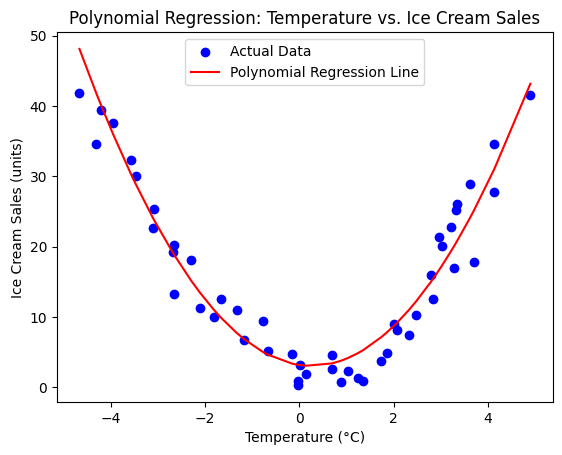

In [ ]:
plt.scatter(x, y, color='blue', label='Actual Data')
plt.plot(x, model.predict(poly_features.transform(x.to_frame())), color='red', label='Polynomial Regression Line')
plt.xlabel('Temperature (°C)')
plt.ylabel('Ice Cream Sales (units)')
plt.title('Polynomial Regression: Temperature vs. Ice Cream Sales')
plt.legend()
plt.show()